# 02 - Customer metrics: sales, frequency, basket value and repeat purchases

**Business question:** How much retailer sales value do households generate, how often do they buy, and how many make repeat purchases?

This notebook builds an exact-decimal SQL customer mart from `transaction_data.csv`, displays SQL alongside results, and uses Pandas to inspect the resulting tables. Shared transformations live in `sql/customer_metrics.sql` and `src/retail_customer_360/metrics.py`.

Results are descriptive for the selected observation window. They do not establish customer acquisition, causal campaign effects, customer lifetime value or future churn. No raw files are modified.

## 1. Definitions and analytical decisions

| Metric | Definition |
|---|---|
| Eligible paid line | `QUANTITY > 0 AND SALES_VALUE > 0` |
| Paid purchase basket | A receipt with at least one eligible line; sales are summed from eligible lines only |
| Retailer sales value | Sum of eligible `SALES_VALUE` in the selected period, in USD; not profit or necessarily customer cash payment |
| Frequency | Number of distinct eligible receipts per household within the selected window |
| Average basket value | Eligible sales divided by eligible receipts; overall value uses total sales / total baskets, not an unweighted average of household averages |
| Repeat buyer | At least two eligible baskets in the selected period; may include same-day visits |
| Multi-day buyer | Eligible purchases on at least two distinct source days |
| Repeat-buyer rate | Repeat buyers / households with at least one eligible basket; denominator shown explicitly |
| Recency | Cutoff day minus last eligible purchase day **within this window**; NULL if none |
| Interpurchase gap | Difference in source days between consecutive eligible receipts, ordered by day then basket ID; same-day gaps are zero |
| Baskets per 30 window days | Basket count / inclusive selected window length x 30; a normalised descriptive rate, not adjusted for customer tenure |

**Population:** all household identifiers observed in source transactions on or before the cutoff, including households with no eligible purchase in this window. Future-only households are excluded. Demographic availability is not required.

**Zero handling:** zero-price products and zero-quantity records remain in raw reconciliation but do not qualify as paid lines. An otherwise valid basket is retained through its eligible lines. This is a modelling choice, not a claim that excluded rows are data errors. AOV here is eligible-line sales per paid basket, not a verified reconstruction of the complete printed receipt.

See [field definitions](../docs/data_dictionary.md) for `SALES_VALUE` and discount caveats. Do not subtract discounts again.

**Step 1: Prepare imports, imports, imports.**

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside retail-customer-360.")
sys.path.insert(0, str(ROOT / "src"))


**Step 2: Import the required libraries.**

In [2]:
from retail_customer_360.metrics import (
    load_transactions,
    build_metrics,
    summary,
    export_metrics,
)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)


**Step 3: Define the show_sql helper.**

In [3]:
def show_sql(query):
    display(Markdown("```sql\n" + query.strip() + "\n```"))


**Step 4: Define the run_sql helper.**

In [4]:
def run_sql(query):
    show_sql(query)
    result = con.execute(query).fetchdf()
    display(result)
    return result


**Step 5: Load data and inspect the input.**

In [5]:
# Monetary strings are checked, negligible zero-quantity residues are flagged,
# and values are converted to DECIMAL(18,2) without binary-float money sums.
# Only transaction_data.csv is read; the large promotion file is not needed here.
con = load_transactions(ROOT)
source_bounds = con.execute("""SELECT min(day), max(day)
FROM raw_transactions""").fetchone()
print("Source day coverage:", source_bounds)


Source day coverage: (1, 711)


## 2. Set the observation window

The default uses all observed transaction days. Change these two parameters and rerun all subsequent cells for a different period. Both boundaries are inclusive. The cutoff cannot exceed the observed horizon. All metrics below are scoped to this window; recency is not a lifetime measure for inactive households.

In [6]:
WINDOW_START_DAY = source_bounds[0]
AS_OF_DAY = source_bounds[1]
build_metrics(con, WINDOW_START_DAY, AS_OF_DAY, ROOT)
display(con.execute("""SELECT *, as_of_day-window_start_day+1 AS window_days
FROM metrics_parameters""").fetchdf())


,window_start_day,as_of_day,window_days
0,1,711,711


## 3. Inspect the SQL building the mart

The transformation has four steps: apply the time window, select paid lines, aggregate receipt-level sales, and aggregate household metrics. `LAG` calculates gaps between consecutive baskets. The household population is left joined to purchases, preserving inactive households.

In [7]:
show_sql((ROOT / "sql/customer_metrics.sql").read_text(encoding="utf-8"))
print(
    "SQL executed above through build_metrics(). All tables are "
    "temporary in-memory analytical tables."
)


```sql
-- Parameters are supplied by Python in metrics_parameters (one row).
-- A paid purchase line has positive quantity AND positive retailer proceeds.
CREATE OR REPLACE TEMP TABLE scoped_transactions AS
SELECT t.* FROM raw_transactions t CROSS JOIN metrics_parameters p
WHERE t.day BETWEEN p.window_start_day AND p.as_of_day;

CREATE OR REPLACE TEMP TABLE eligible_lines AS
SELECT * FROM scoped_transactions WHERE quantity > 0 AND sales_value > 0;

CREATE OR REPLACE TEMP TABLE basket_metrics AS
SELECT household_key, basket_id, day,
       count(*) AS eligible_line_rows,
       sum(sales_value) AS eligible_sales_value
FROM eligible_lines GROUP BY household_key, basket_id, day;

CREATE OR REPLACE TEMP TABLE purchase_intervals AS
SELECT *, day - lag(day) OVER (
    PARTITION BY household_key ORDER BY day, basket_id
) AS days_since_previous_basket
FROM basket_metrics;

CREATE OR REPLACE TEMP TABLE customer_metrics AS
WITH population AS (
    -- Keep previously observed households even if inactive in this window.
    SELECT DISTINCT household_key FROM raw_transactions
    WHERE day <= (SELECT as_of_day FROM metrics_parameters)
), purchases AS (
    SELECT household_key, count(*) AS purchase_baskets,
           count(DISTINCT day) AS purchase_days,
           sum(eligible_sales_value) AS eligible_sales_value,
           min(day) AS first_purchase_day_in_window,
           max(day) AS last_purchase_day_in_window,
           avg(days_since_previous_basket) AS mean_days_between_baskets,
           median(days_since_previous_basket) AS median_days_between_baskets
    FROM purchase_intervals GROUP BY household_key
)
SELECT h.household_key, p.window_start_day, p.as_of_day,
       p.as_of_day - p.window_start_day + 1 AS window_days,
       coalesce(a.purchase_baskets, 0) AS purchase_baskets,
       coalesce(a.purchase_days, 0) AS purchase_days,
       coalesce(a.eligible_sales_value, 0)::DECIMAL(18,2) AS eligible_sales_value,
       a.eligible_sales_value / nullif(a.purchase_baskets, 0) AS average_basket_value,
       a.first_purchase_day_in_window, a.last_purchase_day_in_window,
       p.as_of_day - a.last_purchase_day_in_window AS recency_days,
       coalesce(a.purchase_baskets,0) * 30.0 /
           (p.as_of_day-p.window_start_day+1) AS baskets_per_30_window_days,
       coalesce(a.purchase_baskets,0) >= 2 AS repeat_buyer,
       coalesce(a.purchase_days,0) >= 2 AS multi_day_buyer,
       a.mean_days_between_baskets, a.median_days_between_baskets
FROM population h CROSS JOIN metrics_parameters p
LEFT JOIN purchases a USING(household_key);
```

SQL executed above through build_metrics(). All tables are temporary in-memory analytical tables.


## 4. Reconcile raw and eligible totals

Start with all source rows in the selected period. Show exactly how the paid-line rule changes amounts, receipt counts and household counts. Exclusion reasons below are mutually exclusive; sales can be present on zero-quantity rows, so excluding them can change totals. The raw sales total is available for comparison with the earlier audit; money is now summed with exact decimal arithmetic. The source includes tiny scientific-notation residues on zero-quantity lines. Only nonstandard values with absolute magnitude below `1e-9` USD and zero quantity are accepted and rounded to cents; their original strings are retained in a diagnostic table. Other non-cent formats fail validation.

**Step 8: Calculate and inspect query results.**

In [8]:
normalization = run_sql("""SELECT count(*) AS normalized_residue_rows,
       max(abs(source_numeric_value)) AS largest_absolute_residue_usd
FROM monetary_normalization""")
normalization_examples = run_sql("""SELECT *
FROM monetary_normalization
ORDER BY original_sales_text
LIMIT 10""")
reconciliation = run_sql(
    "SELECT 'raw source window' AS scope, count(*) AS "
    "line_rows,\n    count(DISTINCT basket_id) AS baskets, "
    "count(DISTINCT household_key) AS households,\n    "
    "sum(sales_value) AS sales_value\nFROM scoped_transactions\n"
    "UNION ALL\nSELECT 'eligible paid lines', count(*), "
    "count(DISTINCT basket_id),\n    count(DISTINCT "
    "household_key), sum(sales_value)\nFROM eligible_lines"
)


```sql
SELECT count(*) AS normalized_residue_rows,
       max(abs(source_numeric_value)) AS largest_absolute_residue_usd
FROM monetary_normalization
```

,normalized_residue_rows,largest_absolute_residue_usd
0,29,1.776357e-15


```sql
SELECT *
FROM monetary_normalization
ORDER BY original_sales_text
LIMIT 10
```

,original_sales_text,original_quantity,source_numeric_value
0,1.110223E-16,0,1.110223e-16
1,1.665335E-16,0,1.665335e-16
2,1.776357E-15,0,1.776357e-15
3,1.776357E-15,0,1.776357e-15
4,1.776357E-15,0,1.776357e-15
5,2.220446E-16,0,2.220446e-16
6,2.220446E-16,0,2.220446e-16
7,2.220446E-16,0,2.220446e-16
8,2.220446E-16,0,2.220446e-16
9,2.220446E-16,0,2.220446e-16


```sql
SELECT 'raw source window' AS scope, count(*) AS line_rows,
    count(DISTINCT basket_id) AS baskets, count(DISTINCT household_key) AS households,
    sum(sales_value) AS sales_value
FROM scoped_transactions
UNION ALL
SELECT 'eligible paid lines', count(*), count(DISTINCT basket_id),
    count(DISTINCT household_key), sum(sales_value)
FROM eligible_lines
```

,scope,line_rows,baskets,households,sales_value
0,raw source window,2595732,276484,2500,8057463.08
1,eligible paid lines,2576815,275539,2500,8057443.80


**Step 9: Calculate and inspect query results.**

In [9]:
exclusions = run_sql(
    "SELECT CASE\n    WHEN quantity <= 0 THEN 'excluded: "
    "non-positive quantity'\n    WHEN sales_value <= 0 THEN "
    "'excluded: non-positive sales (positive quantity)'\n    "
    "ELSE 'eligible paid line' END AS eligibility,\n    count(*) "
    "AS line_rows, sum(sales_value) AS source_sales_value\nFROM "
    "scoped_transactions GROUP BY 1 ORDER BY 1"
)
raw_total = con.execute("""SELECT coalesce(sum(sales_value), 0)
FROM scoped_transactions""").fetchone()[0]
paid_total = con.execute("""SELECT coalesce(sum(sales_value), 0)
FROM eligible_lines""").fetchone()[0]
excluded_total = con.execute("""SELECT coalesce(sum(sales_value), 0)
FROM scoped_transactions
WHERE quantity<=0
  OR sales_value<=0""").fetchone()[0]


```sql
SELECT CASE
    WHEN quantity <= 0 THEN 'excluded: non-positive quantity'
    WHEN sales_value <= 0 THEN 'excluded: non-positive sales (positive quantity)'
    ELSE 'eligible paid line' END AS eligibility,
    count(*) AS line_rows, sum(sales_value) AS source_sales_value
FROM scoped_transactions GROUP BY 1 ORDER BY 1
```

,eligibility,line_rows,source_sales_value
0,eligible paid line,2576815,8057443.80
1,excluded: non-positive quantity,14466,19.28
2,excluded: non-positive sales (positive quantity),4451,0.00


**Step 10: Check the calculation.**

In [10]:
assert raw_total == paid_total + excluded_total
print(
    "Exact sales reconciliation passed:",
    raw_total,
    "=",
    paid_total,
    "+",
    excluded_total,
)


Exact sales reconciliation passed: 8057463.08 = 8057443.80 + 19.28


## 5. Business overview

This query calculates overall paid-basket metrics and makes denominators explicit. The pooled average gap weights every consecutive-basket interval equally. It is different from averaging each household's mean gap. First purchases in the window have no prior interval and are excluded from gap averages.

In [11]:
overview = run_sql(
    (ROOT / "sql/customer_metrics_summary.sql").read_text(encoding="utf-8")
)
metrics = summary(con, ROOT)
display(pd.DataFrame([{"metric": k, "value": v} for k, v in metrics.items()]))


```sql
SELECT
    (SELECT window_start_day FROM metrics_parameters) AS window_start_day,
    (SELECT as_of_day FROM metrics_parameters) AS as_of_day,
    count(*) AS observed_households,
    count(*) FILTER (WHERE purchase_baskets > 0) AS purchasing_households,
    sum(purchase_baskets) AS purchase_baskets,
    sum(eligible_sales_value) AS eligible_sales_value,
    sum(eligible_sales_value) / nullif(sum(purchase_baskets),0) AS average_basket_value,
    sum(purchase_baskets) * 1.0 / nullif(count(*) FILTER (WHERE purchase_baskets>0),0)
        AS baskets_per_purchasing_household,
    avg(purchase_baskets) AS baskets_per_observed_household,
    count(*) FILTER (WHERE repeat_buyer) AS repeat_buyers,
    100.0 * count(*) FILTER (WHERE repeat_buyer) /
        nullif(count(*) FILTER (WHERE purchase_baskets>0),0) AS repeat_buyer_pct,
    count(*) FILTER (WHERE multi_day_buyer) AS multi_day_buyers,
    100.0 * count(*) FILTER (WHERE multi_day_buyer) /
        nullif(count(*) FILTER (WHERE purchase_baskets>0),0) AS multi_day_buyer_pct,
    (SELECT avg(days_since_previous_basket) FROM purchase_intervals)
        AS mean_days_between_baskets_pooled,
    (SELECT median(days_since_previous_basket) FROM purchase_intervals)
        AS median_days_between_baskets_pooled
FROM customer_metrics
```

,window_start_day,as_of_day,observed_households,purchasing_households,purchase_baskets,eligible_sales_value,average_basket_value,baskets_per_purchasing_household,baskets_per_observed_household,repeat_buyers,repeat_buyer_pct,multi_day_buyers,multi_day_buyer_pct,mean_days_between_baskets_pooled,median_days_between_baskets_pooled
0,1,711,2500,2500,275539.0,8057443.8,29.24248,110.2156,110.2156,2497,99.88,2497,99.88,5.669736,2.0


,metric,value
0,window_start_day,1
1,as_of_day,711
2,observed_households,2500
3,purchasing_households,2500
4,purchase_baskets,275539
5,eligible_sales_value,8057443.80
6,average_basket_value,29.24248
7,baskets_per_purchasing_household,110.2156
8,baskets_per_observed_household,110.2156
9,repeat_buyers,2497


## 6. Household-level Customer 360 foundation

One row per household observed by the cutoff. Inspect exact basket counts, eligible sales, AOV, first/last eligible purchase days, recency, repeat flags, and gap statistics. A first observed purchase in this window is not an acquisition date. Demographic fields are intentionally not required for this mart.

In [12]:
customers = run_sql("""SELECT *
FROM customer_metrics
ORDER BY household_key
LIMIT 10""")
customer_distribution = run_sql(
    "SELECT\n    min(purchase_baskets) AS min_baskets, "
    "median(purchase_baskets) AS median_baskets,\n    "
    "max(purchase_baskets) AS max_baskets,\n    "
    "median(eligible_sales_value) AS "
    "median_household_sales,\n    median(average_basket_value) "
    "AS median_active_household_aov,\n    count(*) FILTER (WHERE "
    "purchase_baskets=0) AS households_without_paid_baskets\n"
    "FROM customer_metrics"
)


```sql
SELECT *
FROM customer_metrics
ORDER BY household_key
LIMIT 10
```

,household_key,window_start_day,as_of_day,window_days,purchase_baskets,purchase_days,eligible_sales_value,average_basket_value,first_purchase_day_in_window,last_purchase_day_in_window,recency_days,baskets_per_30_window_days,repeat_buyer,multi_day_buyer,mean_days_between_baskets,median_days_between_baskets
0,1,1,711,711,85,78,4330.16,50.943059,51,706,5,3.586498,True,True,7.797619,8.0
1,2,1,711,711,45,45,1954.34,43.429778,103,668,43,1.898734,True,True,12.840909,7.5
2,3,1,711,711,47,46,2653.21,56.451277,113,703,8,1.983122,True,True,12.826087,9.0
3,4,1,711,711,30,30,1200.11,40.003667,104,627,84,1.265823,True,True,18.034483,13.0
4,5,1,711,711,40,33,779.06,19.476500,85,703,8,1.687764,True,True,15.846154,10.0
5,6,1,711,711,249,220,5996.16,24.080964,118,707,4,10.506329,True,True,2.375000,2.0
6,7,1,711,711,59,59,3400.05,57.627966,23,709,2,2.489451,True,True,11.827586,8.5
7,8,1,711,711,113,103,5534.97,48.982035,65,706,5,4.767932,True,True,5.723214,4.0
8,9,1,711,711,20,20,797.42,39.871000,104,689,22,0.843882,True,True,30.789474,14.0
9,10,1,711,711,9,5,234.34,26.037778,114,685,26,0.379747,True,True,71.375000,8.0


```sql
SELECT
    min(purchase_baskets) AS min_baskets, median(purchase_baskets) AS median_baskets,
    max(purchase_baskets) AS max_baskets,
    median(eligible_sales_value) AS median_household_sales,
    median(average_basket_value) AS median_active_household_aov,
    count(*) FILTER (WHERE purchase_baskets=0) AS households_without_paid_baskets
FROM customer_metrics
```

,min_baskets,median_baskets,max_baskets,median_household_sales,median_active_household_aov,households_without_paid_baskets
0,1,78.0,1298,2157.75,27.488567,0


## 7. Follow one household from receipt lines to its metrics

Choose the smallest identifier with at least two paid baskets. First display a small part of its raw history, then aggregate all its eligible baskets, then show its one-row customer record. The limited examples illustrate the calculation; the complete mart uses every eligible row.

**Step 13: Calculate and inspect query results.**

In [13]:
example_household = con.execute("""SELECT min(household_key)
FROM customer_metrics
WHERE purchase_baskets>=2""").fetchone()[0]
if example_household is None:
    print("No repeat buyer in this window; widen the window to inspect an example.")
else:
    h = int(example_household)
    example_lines = run_sql(
        "SELECT *, quantity>0 AND sales_value>0 AS eligible_paid_line\n    FROM"
        f" scoped_transactions WHERE household_key={h}\n    ORDER BY"
        " day,basket_id,product_id,sales_value LIMIT 15"
    )


```sql
SELECT *, quantity>0 AND sales_value>0 AS eligible_paid_line
    FROM scoped_transactions WHERE household_key=1
    ORDER BY day,basket_id,product_id,sales_value LIMIT 15
```

,household_key,basket_id,day,product_id,quantity,sales_value,eligible_paid_line
0,1,27601281299,51,825123,1,3.99,True
1,1,27601281299,51,831447,1,2.99,True
2,1,27601281299,51,840361,1,1.09,True
3,1,27601281299,51,845307,1,3.71,True
4,1,27601281299,51,852014,1,2.79,True
5,1,27601281299,51,854982,1,7.19,True
6,1,27601281299,51,856942,1,2.50,True
7,1,27601281299,51,912676,1,1.49,True
8,1,27601281299,51,940947,2,2.99,True
9,1,27601281299,51,945805,1,1.39,True


**Step 14: Calculate and inspect query results.**

In [14]:
if example_household is None:
    pass
else:
    example_baskets = run_sql(
        "SELECT basket_id,day,eligible_line_rows,"
        "eligible_sales_value,\n        days_since_previous_basket "
        "FROM purchase_intervals WHERE household_key="
        f"{h}"
        "\n    ORDER BY day,basket_id LIMIT 15"
    )
    example_customer = run_sql(
        f"SELECT * FROM customer_metrics WHERE household_key={h}"
    )


```sql
SELECT basket_id,day,eligible_line_rows,eligible_sales_value,
        days_since_previous_basket FROM purchase_intervals WHERE household_key=1
    ORDER BY day,basket_id LIMIT 15
```

,basket_id,day,eligible_line_rows,eligible_sales_value,days_since_previous_basket
0,27601281299,51,30,78.66,<NA>
1,27774192959,67,11,41.10,16
2,28024266849,88,12,26.90,21
3,28106322445,94,22,63.43,6
4,28235481967,101,17,53.45,7
5,28282581446,108,10,26.76,7
6,28318295376,111,9,23.55,3
7,28601601153,128,39,110.34,17
8,28744672720,137,35,87.44,9
9,28853646373,146,29,73.32,9


```sql
SELECT * FROM customer_metrics WHERE household_key=1
```

,household_key,window_start_day,as_of_day,window_days,purchase_baskets,purchase_days,eligible_sales_value,average_basket_value,first_purchase_day_in_window,last_purchase_day_in_window,recency_days,baskets_per_30_window_days,repeat_buyer,multi_day_buyer,mean_days_between_baskets,median_days_between_baskets
0,1,1,711,711,85,78,4330.16,50.943059,51,706,5,3.586498,True,True,7.797619,8.0


## 8. Frequency and repeat purchases

Group households by paid basket count. Percentages use the full observed population; repeat-buyer rates in section 5 use purchasing households. Both denominators are useful but must not be confused. Near-universal repeat purchasing over a long window does not imply equally high short-term retention.

Two receipts on the same day count as two baskets but only one purchase day. The multi-day flag makes that distinction visible.

**Step 15: Calculate and inspect query results.**

In [15]:
frequency_groups = run_sql(
    """SELECT CASE WHEN purchase_baskets=0 THEN '0' WHEN purchase_baskets=1 THEN '1'
           WHEN purchase_baskets BETWEEN 2 AND 5 THEN '2-5'
           WHEN purchase_baskets BETWEEN 6 AND 20 THEN '6-20'
           WHEN purchase_baskets BETWEEN 21 AND 50 THEN '21-50' ELSE '51+'
       END AS basket_count_group, count(*) AS households,
       100.0*count(*)/
  (SELECT count(*)
   FROM customer_metrics) AS observed_household_pct
FROM customer_metrics
GROUP BY 1
ORDER BY min(purchase_baskets)"""
)


```sql
SELECT CASE WHEN purchase_baskets=0 THEN '0' WHEN purchase_baskets=1 THEN '1'
           WHEN purchase_baskets BETWEEN 2 AND 5 THEN '2-5'
           WHEN purchase_baskets BETWEEN 6 AND 20 THEN '6-20'
           WHEN purchase_baskets BETWEEN 21 AND 50 THEN '21-50' ELSE '51+'
       END AS basket_count_group, count(*) AS households,
       100.0*count(*)/
  (SELECT count(*)
   FROM customer_metrics) AS observed_household_pct
FROM customer_metrics
GROUP BY 1
ORDER BY min(purchase_baskets)
```

,basket_count_group,households,observed_household_pct
0,1,3,0.12
1,2-5,31,1.24
2,6-20,253,10.12
3,21-50,563,22.52
4,51+,1650,66.00


**Step 16: Calculate and inspect query results.**

In [16]:
repeat_groups = run_sql("""SELECT repeat_buyer,multi_day_buyer,count(*) AS households
FROM customer_metrics
GROUP BY ALL
ORDER BY repeat_buyer,multi_day_buyer""")


```sql
SELECT repeat_buyer,multi_day_buyer,count(*) AS households
FROM customer_metrics
GROUP BY ALL
ORDER BY repeat_buyer,multi_day_buyer
```

,repeat_buyer,multi_day_buyer,households
0,False,False,3
1,True,True,2497


## 9. Time between purchases and source-period trends

Intervals are measured within the window, including zero-day gaps. There is no interval before the first eligible basket in the window. Fixed 30-source-day blocks are not calendar months; the final block can be shorter, so display its exposure length alongside totals.

**Step 17: Calculate and inspect query results.**

In [17]:
gaps = run_sql(
    "SELECT count(days_since_previous_basket) AS "
    "observed_intervals,\n    count(*) FILTER (WHERE "
    "days_since_previous_basket=0) AS same_day_intervals,\n    "
    "avg(days_since_previous_basket) AS "
    "pooled_mean_gap_days,\n    "
    "median(days_since_previous_basket) AS "
    "pooled_median_gap_days,\n    "
    "quantile_cont(days_since_previous_basket,0.9) AS "
    "pooled_p90_gap_days\nFROM purchase_intervals"
)


```sql
SELECT count(days_since_previous_basket) AS observed_intervals,
    count(*) FILTER (WHERE days_since_previous_basket=0) AS same_day_intervals,
    avg(days_since_previous_basket) AS pooled_mean_gap_days,
    median(days_since_previous_basket) AS pooled_median_gap_days,
    quantile_cont(days_since_previous_basket,0.9) AS pooled_p90_gap_days
FROM purchase_intervals
```

,observed_intervals,same_day_intervals,pooled_mean_gap_days,pooled_median_gap_days,pooled_p90_gap_days
0,273039,50255,5.669736,2.0,12.0


**Step 18: Calculate and inspect query results.**

In [18]:
period_trends = run_sql(
    "SELECT\n    p.window_start_day + "
    "30*floor((b.day-p.window_start_day)/30.0)::INTEGER AS "
    "block_start_day,\n    least(block_start_day+29,p.as_of_day) "
    "AS block_end_day,\n    block_end_day-block_start_day+1 AS "
    "exposure_days,\n    count(*) AS paid_baskets, "
    "count(DISTINCT b.household_key) AS "
    "purchasing_households,\n    sum(b.eligible_sales_value) AS "
    "eligible_sales_value,\n    "
    "sum(b.eligible_sales_value)/count(*) AS "
    "average_basket_value\nFROM basket_metrics b CROSS JOIN "
    "metrics_parameters p\nGROUP BY block_start_day,p.as_of_day "
    "ORDER BY block_start_day"
)


```sql
SELECT
    p.window_start_day + 30*floor((b.day-p.window_start_day)/30.0)::INTEGER AS block_start_day,
    least(block_start_day+29,p.as_of_day) AS block_end_day,
    block_end_day-block_start_day+1 AS exposure_days,
    count(*) AS paid_baskets, count(DISTINCT b.household_key) AS purchasing_households,
    sum(b.eligible_sales_value) AS eligible_sales_value,
    sum(b.eligible_sales_value)/count(*) AS average_basket_value
FROM basket_metrics b CROSS JOIN metrics_parameters p
GROUP BY block_start_day,p.as_of_day ORDER BY block_start_day
```

,block_start_day,block_end_day,exposure_days,paid_baskets,purchasing_households,eligible_sales_value,average_basket_value
0,1,30,30,1885,527,55507.41,29.446902
1,31,60,30,4281,972,120996.64,28.263639
2,61,90,30,7974,1552,214878.77,26.947425
3,91,120,30,11966,2141,317907.82,26.567593
4,121,150,30,12957,1996,341839.33,26.382599
5,151,180,30,12964,1997,358687.39,27.667957
6,181,210,30,12194,1979,347066.32,28.462057
7,211,240,30,12276,1987,341184.47,27.792805
8,241,270,30,12536,2006,373605.18,29.802583
9,271,300,30,12415,2018,379657.88,30.580578


## Visual exploration: time, frequency, purchase gaps and concentration

These four figures use the same eligible paid baskets and observation window as the metric tables. Plots are descriptive and saved under `reports/figures/`. No calendar dates are assumed. Distribution charts retain the full observed range, including inactive households and zero-day repeat visits.

**Step 19: Prepare imports, imports, imports.**

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, TEAL = "#245C83", "#D77931", "#208778"


**Step 20: Define the finish_figure helper.**

In [20]:
from IPython.display import Image as NotebookImage


def finish_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / filename)))
    plt.close(fig)


**Step 21: Prepare window label.**

In [21]:
window_label = f"Source days {WINDOW_START_DAY} to {AS_OF_DAY}; eligible paid baskets"


### A. What drives sales over time?

Use original `WEEK_NO` identifiers. Verify that each observed source day maps to one week, then aggregate eligible basket sales. AOV is calculated as sales / baskets within each week. A week with fewer than seven observed transaction days is marked orange; observation coverage, not necessarily business closure, can explain a low total. Do not interpret an incomplete edge week as a sales decline.

**Step 22: Load data and inspect the input.**

In [22]:
con.execute(
    """CREATE OR REPLACE TEMP TABLE source_day_week AS
SELECT DISTINCT day::INTEGER AS day, week_no::INTEGER AS week_no
FROM read_csv(?, header=true, all_varchar=true)""",
    [str(ROOT / "data/raw/transaction_data.csv")],
)
assert con.execute("""SELECT count(*)
FROM
  (SELECT day
   FROM source_day_week
   GROUP BY day
   HAVING count(*)>1)""").fetchone()[0] == 0


**Step 23: Calculate and inspect query results.**

**Inspect week coverage before comparing sales.**

In [23]:
con.execute("""CREATE OR REPLACE TEMP VIEW weekly_coverage AS
SELECT week_no, count(*) AS observed_days
FROM source_day_week
WHERE day BETWEEN
    (SELECT window_start_day FROM metrics_parameters)
    AND (SELECT as_of_day FROM metrics_parameters)
GROUP BY week_no""")
weekly_coverage = run_sql("SELECT * FROM weekly_coverage ORDER BY week_no")


```sql
SELECT * FROM weekly_coverage ORDER BY week_no
```

,week_no,observed_days
0,1,5
1,2,7
2,3,7
3,4,7
4,5,7
...,...,...
97,98,7
98,99,7
99,100,7
100,101,7


**Calculate weekly basket totals separately.**

In [24]:
con.execute("""CREATE OR REPLACE TEMP VIEW weekly_totals AS
SELECT w.week_no, count(*) AS paid_baskets,
    sum(b.eligible_sales_value) AS sales,
    sum(b.eligible_sales_value) / count(*) AS average_basket_value
FROM basket_metrics b
JOIN source_day_week w USING(day)
GROUP BY w.week_no""")
weekly_totals = run_sql("SELECT * FROM weekly_totals ORDER BY week_no LIMIT 10")


```sql
SELECT * FROM weekly_totals ORDER BY week_no LIMIT 10
```

,week_no,paid_baskets,sales,average_basket_value
0,1,139,5211.16,37.490360
1,2,321,10821.35,33.711371
2,3,480,13498.13,28.121104
3,4,543,15965.99,29.403297
4,5,753,20139.82,26.746109
5,6,855,24923.90,29.150760
6,7,994,28073.97,28.243431
7,8,1083,31793.77,29.357128
8,9,1203,31244.17,25.971879
9,10,1533,42994.38,28.045910


**Combine totals with observed-day coverage.**

In [25]:
weekly = run_sql("""SELECT c.*,
    coalesce(t.paid_baskets, 0) AS paid_baskets,
    coalesce(t.sales, 0) AS sales,
    t.average_basket_value
FROM weekly_coverage c
LEFT JOIN weekly_totals t USING(week_no)
ORDER BY week_no""")


```sql
SELECT c.*,
    coalesce(t.paid_baskets, 0) AS paid_baskets,
    coalesce(t.sales, 0) AS sales,
    t.average_basket_value
FROM weekly_coverage c
LEFT JOIN weekly_totals t USING(week_no)
ORDER BY week_no
```

,week_no,observed_days,paid_baskets,sales,average_basket_value
0,1,5,139,5211.16,37.490360
1,2,7,321,10821.35,33.711371
2,3,7,480,13498.13,28.121104
3,4,7,543,15965.99,29.403297
4,5,7,753,20139.82,26.746109
...,...,...,...,...,...
97,98,7,3027,98949.03,32.688811
98,99,7,2841,101363.92,35.678958
99,100,7,2784,93063.10,33.427838
100,101,7,2675,84407.25,31.554112


**Step 24: Build the chart.**

In [26]:
fig = Figure(figsize=(12, 8))
axes = fig.subplots(3, 1, sharex=True)
colors = np.where(weekly.observed_days < 7, ORANGE, BLUE)
for ax, col, label in zip(
    axes,
    ["sales", "paid_baskets", "average_basket_value"],
    ["Retailer sales (USD)", "Paid baskets", "Average basket (USD)"],
):
    ax.bar(weekly.week_no, weekly[col], color=colors, width=0.85)
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[-1].set_xlabel("Original source week (not calendar week)")
axes[0].set_title(
    "Sales, basket count and average basket value by source week",
    loc="left",
    fontweight="bold",
)


Text(0.0, 1.0, 'Sales, basket count and average basket value by source week')

**Step 25: Finish and display the chart.**

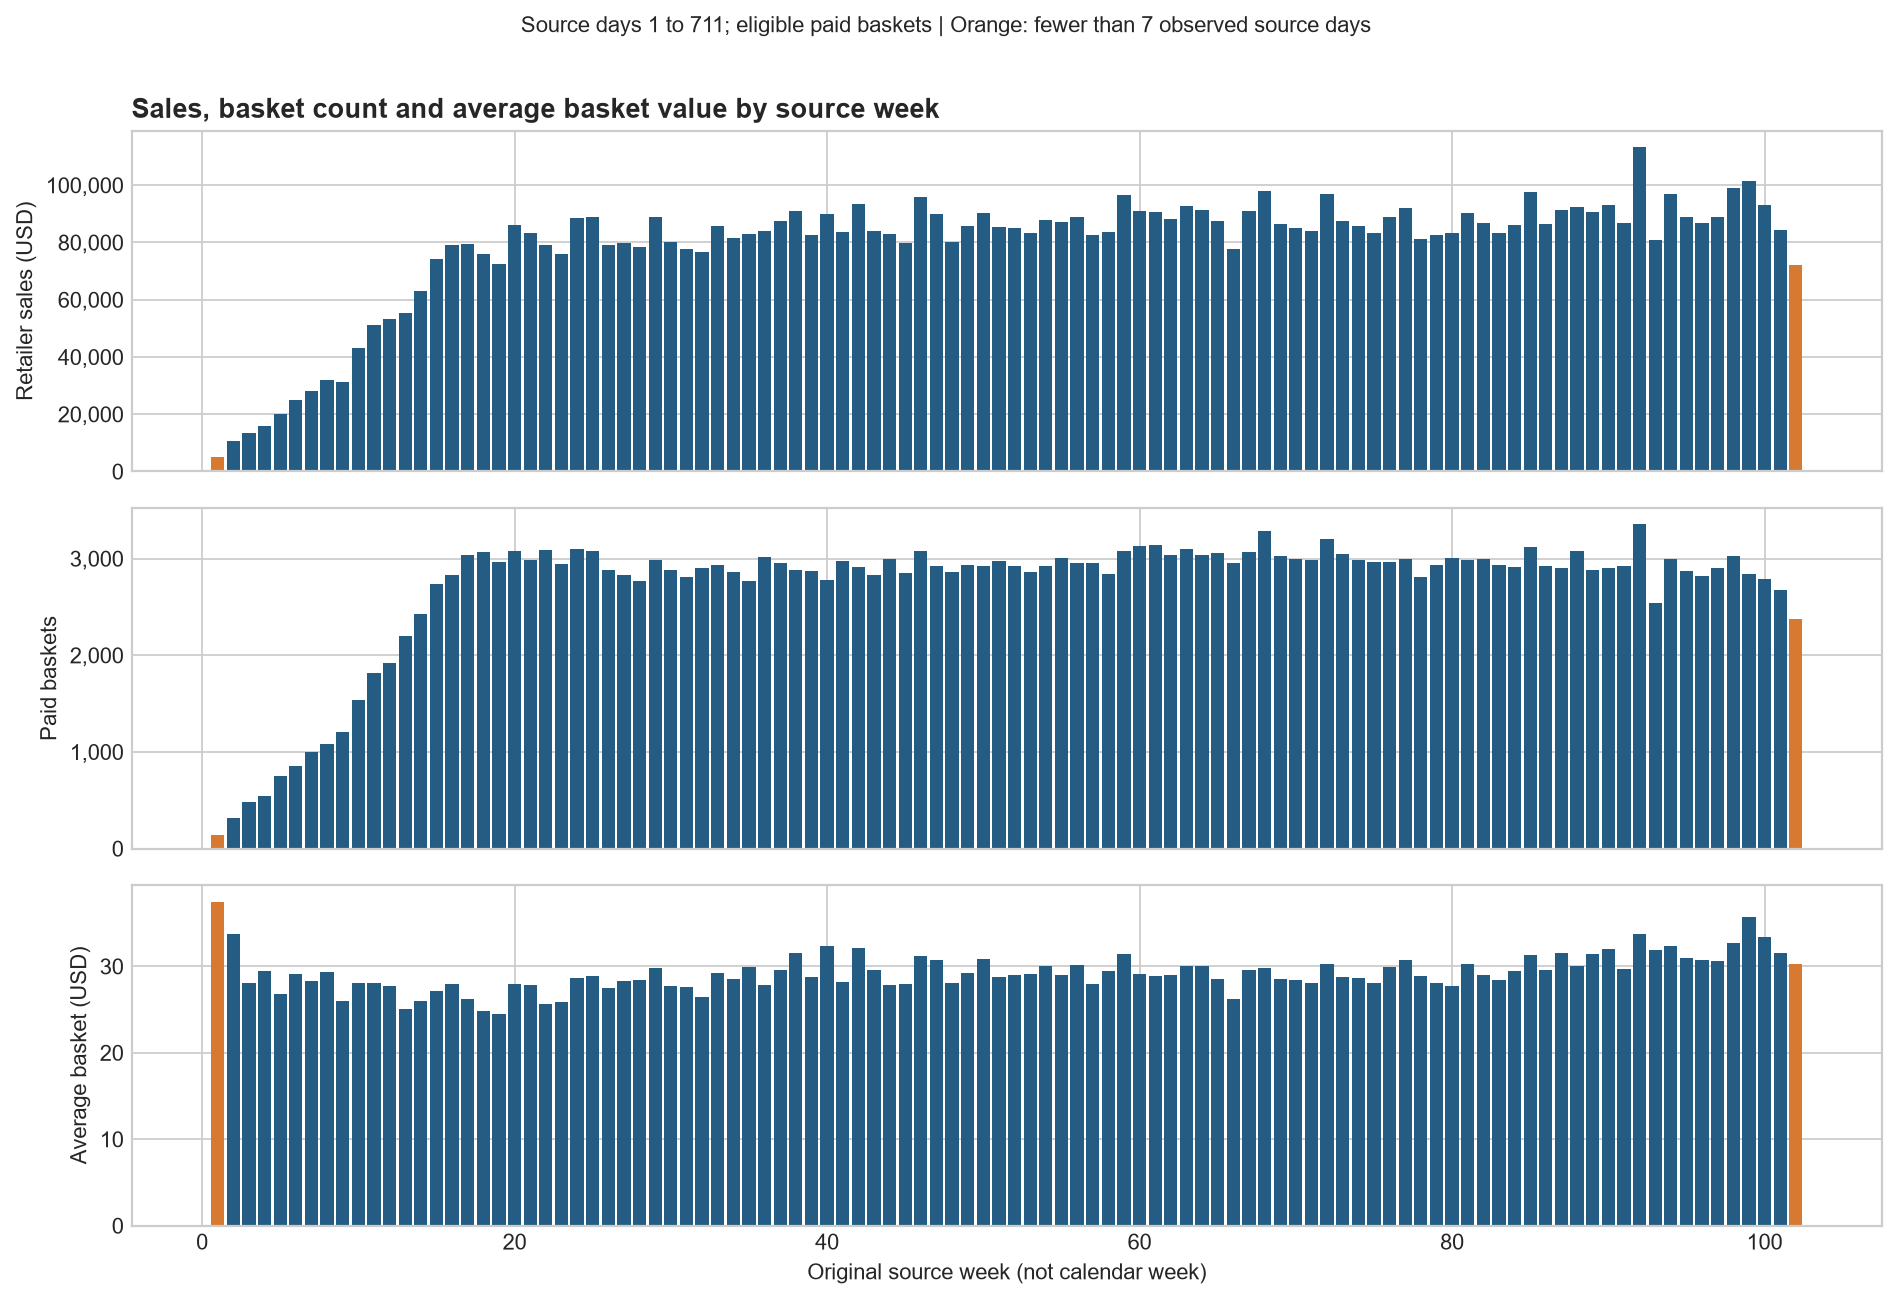

,week_no,observed_days,paid_baskets,sales
0,1,5,139,5211.16
101,102,6,2375,71968.63


In [27]:
fig.suptitle(
    window_label + " | Orange: fewer than 7 observed source days", fontsize=10, y=1.01
)
finish_figure(fig, "02_weekly_sales_baskets_aov.png")
display(
    weekly.loc[
        weekly.observed_days < 7, ["week_no", "observed_days", "paid_baskets", "sales"]
    ]
)


### B. How different are household purchase frequencies?

Each household contributes once. Frequency counts eligible baskets within the selected window. The median and upper percentiles show how much a single average can hide; all household counts, including zeros, remain visible.

**Step 26: Build the chart.**

In [28]:
household_plot = con.execute(
    """SELECT household_key,purchase_baskets,eligible_sales_value
FROM customer_metrics
ORDER BY household_key"""
).fetchdf()
freq = household_plot.purchase_baskets.to_numpy()
fig = Figure(figsize=(11, 4.5))
ax = fig.subplots()
ax.hist(freq, bins=40, color=BLUE, edgecolor="white")
for q, color in [(50, TEAL), (90, ORANGE), (99, "#8D4A70")]:
    value = float(np.percentile(freq, q))
    ax.axvline(value, color=color, linestyle="--", label=f"p{q}: {value:.1f}")
ax.set(
    xlabel="Eligible baskets per household in selected window",
    ylabel="Households",
    title="Household purchase frequency: full observed range",
)


[Text(0.5, 0, 'Eligible baskets per household in selected window'),
 Text(0, 0.5, 'Households'),
 Text(0.5, 1.0, 'Household purchase frequency: full observed range')]

In [29]:
display(household_plot.head())


,household_key,purchase_baskets,eligible_sales_value
0,1,85,4330.16
1,2,45,1954.34
2,3,47,2653.21
3,4,30,1200.11
4,5,40,779.06


**Step 27: Finish and display the chart.**

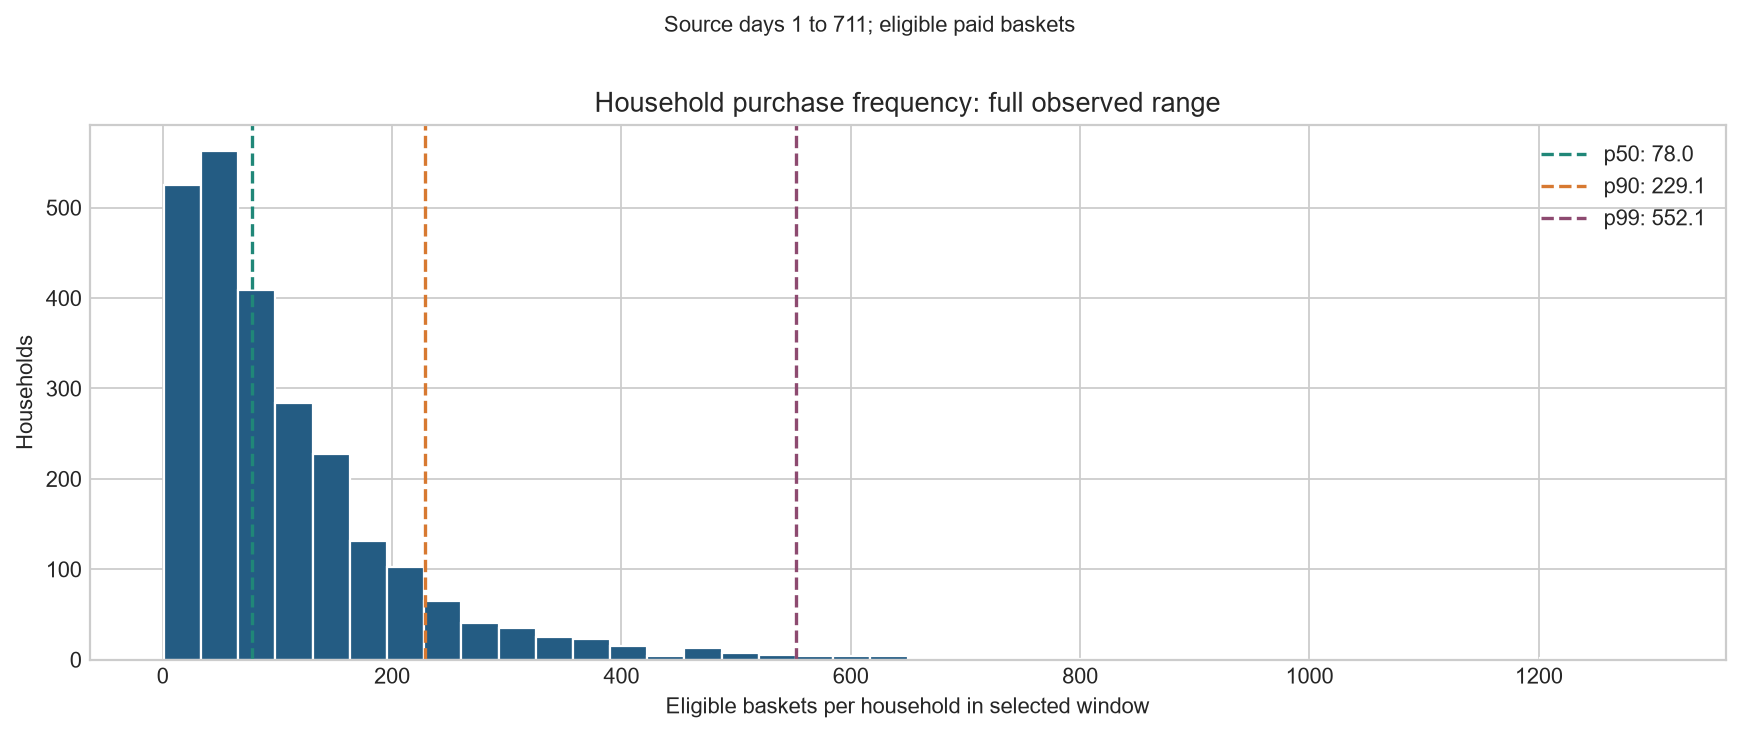

In [30]:
ax.legend(frameon=False)
fig.suptitle(window_label, fontsize=10, y=1.01)
finish_figure(fig, "02_household_frequency.png")


### C. What is the observed time between visits?

Each consecutive-basket interval contributes once. Same-day receipts have a zero gap. Log-spaced bins and a `symlog` x-axis keep both zero-day visits and the long tail visible; bar heights are counts per unequal-width bin, not a probability density. This is not a churn threshold or a retention curve.

**Step 28: Build the chart.**

In [31]:
gap_values = (
    con.execute("""SELECT days_since_previous_basket
FROM purchase_intervals
WHERE days_since_previous_basket IS NOT NULL""")
    .fetchdf()
    .days_since_previous_basket.to_numpy()
)
fig = Figure(figsize=(11, 4.5))
ax = fig.subplots()


**Step 29: Build the chart.**

In [32]:
if len(gap_values):
    maximum = max(1, int(gap_values.max()))
    edges = np.unique(np.r_[0, np.geomspace(1, maximum + 1, 35)])
    ax.hist(gap_values, bins=edges, color=TEAL, edgecolor="white")
    ax.set_xscale("symlog", linthresh=1)
    for q, color in [(50, BLUE), (90, ORANGE)]:
        value = float(np.percentile(gap_values, q))
        ax.axvline(value, color=color, linestyle="--", label=f"p{q}: {value:.1f} days")
    ax.legend(frameon=False)
else:
    ax.text(
        0.5,
        0.5,
        "No consecutive-basket intervals in this window",
        transform=ax.transAxes,
        ha="center",
    )


**Step 30: Build the chart.**

In [33]:
if len(gap_values):
    ax.text(
        0.99,
        0.94,
        f"Same-day intervals: {(gap_values == 0).mean():.1%}\nIntervals:"
        f" {len(gap_values):,}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"),
    )
ax.set(
    xlabel="Days between paid baskets (symlog scale; unequal bin widths)",
    ylabel="Observed intervals per bin",
    title="Interpurchase gaps: zero-day visits and full observed tail",
)


[Text(0.5, 0, 'Days between paid baskets (symlog scale; unequal bin widths)'),
 Text(0, 0.5, 'Observed intervals per bin'),
 Text(0.5, 1.0, 'Interpurchase gaps: zero-day visits and full observed tail')]

**Step 31: Finish and display the chart.**

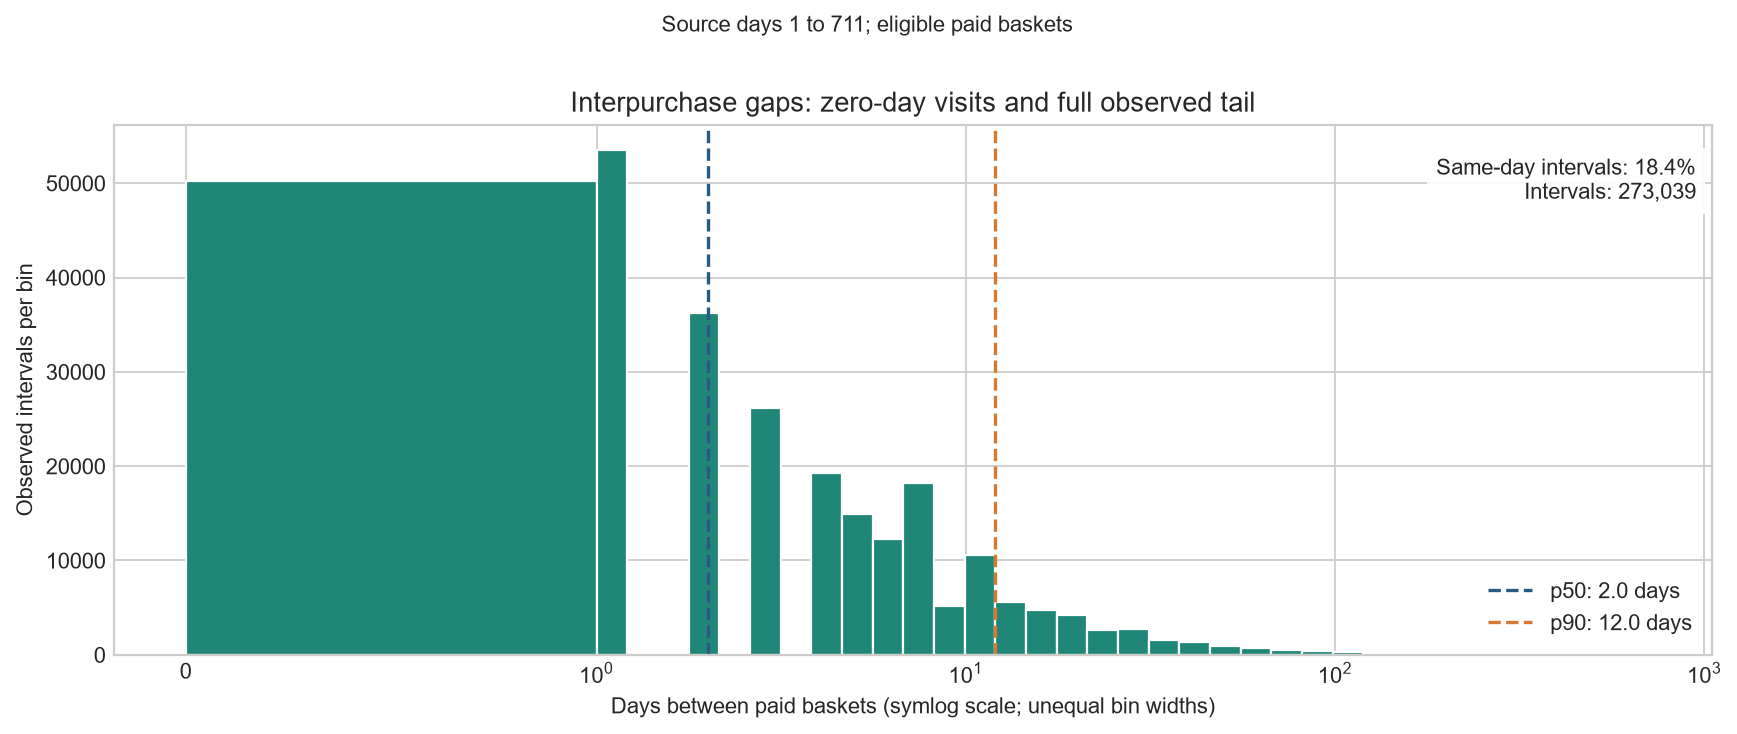

In [34]:
fig.suptitle(window_label, fontsize=10, y=1.01)
finish_figure(fig, "02_interpurchase_gaps.png")


### D. How concentrated are household sales?

Order households by descending eligible sales, then accumulate their share. The diagonal represents equal sales per household; the curve shows actual concentration. This is a concentration curve ordered from highest to lowest spend, not a conventional ascending-order Lorenz curve. Top-group sizes are rounded up to whole households.

**Step 32: Build the chart.**

In [35]:
ordered = household_plot.sort_values(
    ["eligible_sales_value", "household_key"], ascending=[False, True]
).reset_index(drop=True)
sales_values = ordered.eligible_sales_value.to_numpy(dtype=float)
fig = Figure(figsize=(8, 5))
ax = fig.subplots()
concentration = []


In [36]:
display(ordered.head())


,household_key,purchase_baskets,eligible_sales_value
0,1023,601,38319.79
1,1609,408,27859.68
2,2322,323,23646.92
3,1453,761,21661.29
4,2459,970,20671.50


**Step 33: Build the chart.**

In [37]:
if sales_values.sum() > 0:
    x = np.arange(1, len(ordered) + 1) / len(ordered)
    y = np.cumsum(sales_values) / sales_values.sum()
    ax.plot(
        np.r_[0, x],
        np.r_[0, y],
        color=BLUE,
        linewidth=2.5,
        label="Observed sales concentration",
    )
else:
    ax.text(
        0.5,
        0.5,
        "No eligible sales in this window",
        transform=ax.transAxes,
        ha="center",
    )


**Step 34: Build the chart.**

In [38]:
if sales_values.sum() > 0:
    ax.plot(
        [0, 1], [0, 1], color="grey", linestyle="--", label="Equal sales per household"
    )


**Step 35: Build the chart.**

In [39]:
if sales_values.sum() > 0:
    for share in [0.1, 0.2]:
        n = int(np.ceil(len(ordered) * share))
        value = float(y[n - 1])
        concentration.append({
            "top_households": n,
            "household_share_pct": 100 * n / len(ordered),
            "sales_share_pct": 100 * value,
        })
        ax.scatter(n / len(ordered), value, color=ORANGE, zorder=3)
        ax.annotate(
            f"Top {n:,}: {value:.1%} of sales",
            (n / len(ordered), value),
            xytext=(12, -5),
            textcoords="offset points",
            fontsize=9,
        )


**Step 36: Finish and display the chart.**

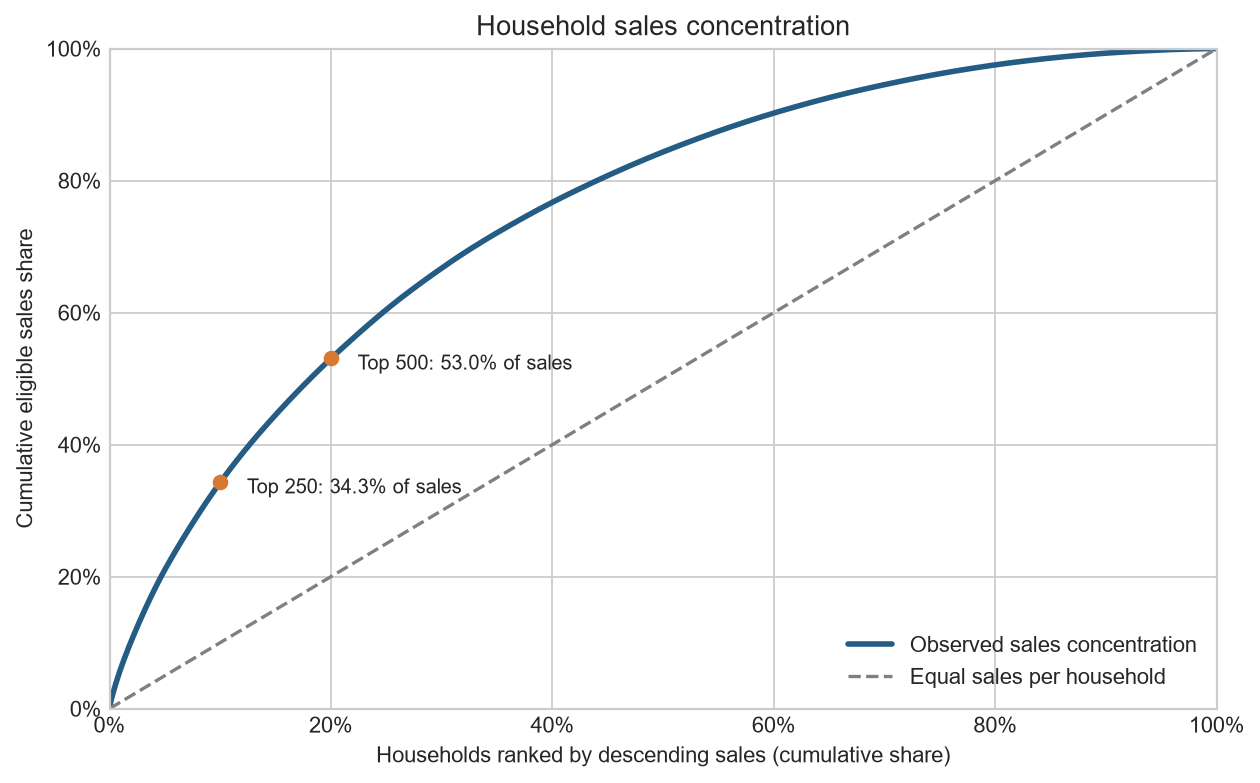

,top_households,household_share_pct,sales_share_pct
0,250,10.0,34.291386
1,500,20.0,53.046404


In [40]:
ax.set(
    xlabel="Households ranked by descending sales (cumulative share)",
    ylabel="Cumulative eligible sales share",
    xlim=(0, 1),
    ylim=(0, 1),
    title="Household sales concentration",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right", frameon=False)
finish_figure(fig, "02_household_sales_concentration.png")
display(pd.DataFrame(concentration))


## 10. Reconciliation and safeguards

Check unique household grain, positive paid baskets, nonnegative intervals, exact sales reconciliation across line/basket/customer levels, and matching basket totals. SQL checks also ensure that no analytical rows exceed the selected window. These assertions fail visibly if the mart is inconsistent.

**Step 37: Check the calculation.**

In [41]:
household_rows, household_ids = con.execute(
    """SELECT count(*),count(DISTINCT household_key)
FROM customer_metrics"""
).fetchone()
assert household_rows == household_ids
basket_total = con.execute("""SELECT coalesce(sum(eligible_sales_value), 0)
FROM basket_metrics""").fetchone()[0]
customer_total = con.execute("""SELECT coalesce(sum(eligible_sales_value), 0)
FROM customer_metrics""").fetchone()[0]
assert paid_total == basket_total == customer_total
assert con.execute("""SELECT count(*)
FROM basket_metrics""").fetchone()[0] == metrics["purchase_baskets"]
assert con.execute("""SELECT count(*)
FROM purchase_intervals
WHERE days_since_previous_basket<0""").fetchone()[0] == 0


**Step 38: Check the calculation.**

In [42]:
assert con.execute("""SELECT count(*)
FROM basket_metrics
WHERE eligible_sales_value<=0""").fetchone()[0] == 0
assert (
    con.execute(
        """SELECT count(*)
FROM scoped_transactions
WHERE day<?
  OR day>?""",
        [WINDOW_START_DAY, AS_OF_DAY],
    ).fetchone()[0]
    == 0
)


**Step 39: Continue the calculation.**

In [43]:
print(
    "Passed: household grain, exact sales, basket counts, time "
    "bounds, positive paid baskets and nonnegative gaps."
)


Passed: household grain, exact sales, basket counts, time bounds, positive paid baskets and nonnegative gaps.


## 11. Export local analytical tables

Exports are written only under the Git-ignored `data/processed/` directory. These are regenerated snapshots for the current parameters; rerunning with another window replaces them. Keep code and methodology in Git, not household-level datasets.

In [44]:
output_dir = export_metrics(con, ROOT)
print("Created local exports:")
for name in [
    "customer_metrics.parquet",
    "customer_metrics.csv",
    "basket_metrics.parquet",
    "customer_metrics_summary.json",
]:
    print("data/processed/" + name)


Created local exports:


data/processed/customer_metrics.parquet
data/processed/customer_metrics.csv
data/processed/basket_metrics.parquet
data/processed/customer_metrics_summary.json


## 12. Findings from the executed calculations

The following text is generated from the computed metrics. Sales are eligible retailer sales, and rates are conditional on the displayed observation window.

**Step 41: Prepare m, final metrics.**

In [45]:
m = metrics
final_metrics = {
    "Window start day": m["window_start_day"],
    "Window end day": m["as_of_day"],
    "Eligible retailer sales (USD)": m["eligible_sales_value"],
    "Excluded sales (USD)": excluded_total,
    "Paid baskets": m["purchase_baskets"],
    "Purchasing households": m["purchasing_households"],
    "Observed households": m["observed_households"],
    "Average basket value (USD)": m["average_basket_value"],
    "Baskets per purchasing household": m["baskets_per_purchasing_household"],
    "Repeat buyers": m["repeat_buyers"],
    "Repeat buyers (%)": m["repeat_buyer_pct"],
    "Multi-day buyers": m["multi_day_buyers"],
    "Multi-day buyers (%)": m["multi_day_buyer_pct"],
}


**Step 42: Inspect the intermediate result.**

In [46]:
display(pd.Series(final_metrics, name="Value").to_frame())
con.close()


,Value
Window start day,1
Window end day,711
Eligible retailer sales (USD),8057443.80
Excluded sales (USD),19.28
Paid baskets,275539
Purchasing households,2500
Observed households,2500
Average basket value (USD),29.24248
Baskets per purchasing household,110.2156
Repeat buyers,2497


## Interpretation limits and next steps

- Full-period repeat purchasing is not a 30-day retention rate; the source population was selected from frequent shoppers, so it does not represent all grocery customers.
- Sales describe the retailer's recorded proceeds, not margin, profit, customer payment, or incremental campaign impact.
- Gap statistics exclude intervals across the window boundaries and can be affected by incomplete observation. First observed purchases are not verified acquisitions.
- Zero-quantity positive-sales lines are excluded explicitly. Investigate their meaning and compare alternative policies before treating this definition as final.
- This notebook is descriptive. Do not use an all-history snapshot as a historical model feature table without rebuilding it for the appropriate cutoff and feature window.
- Next: choose lookback windows for RFM, inspect extreme quantities and excluded lines, and build retention/cohort analysis with clearly defined denominators.